# 2.3 · PD: adaptation effects within each backbone

← [2.2 · LGD: continued synthetic pretraining](<2.2_lgd_finetuning.ipynb>) · → [2.4 · LGD: adaptation effects within each backbone](<2.4_lgd_results.ipynb>)

The paper’s efficacy question is answered by complete final paired comparisons. Learning curves, pipeline PASS receipts and prior resemblance remain separate evidence.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, pathlib
ROOT = pathlib.Path.cwd()
while not (ROOT / "src" / "visualize").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from src.visualize import figures, style, paper_plots as paper, campaign
style.apply()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 80)
FIGS = figures.FigureSaver("2.3_pd_results")
TASK = "pd"
EXP = "exp2"
READY = paper.final_ready(TASK, EXP)
HAS_OOD = paper.ood_ready(TASK, EXP)
HAS_COMPONENTS = EXP == "exp1" and paper.components_ready(TASK)


## A · Development and the comparison contract
Complete final development results determine the mixture; the training recipe is fixed. The
designated holdout is excluded from the current selection statistic but has historical project
exposure, so it is not untouched confirmation. Every final comparison uses common five-fold
assignments, all eligible rows and all prediction-time-eligible features. Small seed marks are
training replicates; the uncertainty unit is the dataset after fold/seed averaging.

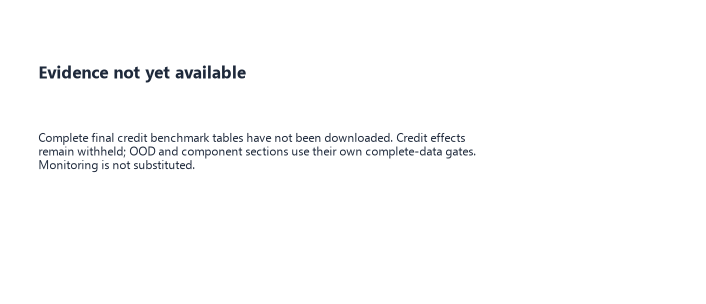

In [2]:
if READY:
    FIGS.save(paper.development_selection(TASK, EXP), "development_selection",
        caption="Complete current-protocol final development ROC-AUC or R² per configuration, with one point per training seed after fold and dataset averaging and a horizontal span for its seed range; released references remain separate.");
else:
    FIGS.save(campaign.availability("Complete final credit benchmark tables have not been downloaded. Credit effects remain withheld; OOD and component sections use their own complete-data gates. Monitoring is not substituted."), "final_benchmark_availability",
        caption="Availability notice for complete final five-fold benchmark tables; the paired-effect axes are withheld until the benchmark coverage and current-protocol gates pass.");

## B · What is the matched-budget package effect on the designated holdout?
Raw differences are treatment minus comparator. ROC-AUC/R² improve upward; log loss, CRPS and
endpoint-mass error improve downward. The main comparator is the equally trained 0% prior within
the same architecture. Lines show descriptive nominal 95% paired-dataset bootstrap intervals;
large dots are means and small marks are individual training seeds. Sparse LGD portfolios imply
limited across-dataset precision, not extra independent observations from folds.

In [3]:
if READY:
    FIGS.save(paper.paired_scores(TASK, EXP), "paired_credit_effect",
        caption="Final designated-holdout metric differences against each architecture’s equally trained 0% control, paired within dataset and training seed; large dots are means, lines nominal 95% dataset bootstrap intervals, and small marks individual training seeds.");
    FIGS.save(paper.dataset_effects(TASK, EXP), "per_dataset_control_gap",
        caption="Mean final ROC-AUC or R² difference against the architecture-matched 0% control per designated-holdout dataset and mixture, averaging folds and training seeds within each dataset.");

### B2 · Does adaptation also improve the released weights?
This is a separate comparator, not a substitute for the equally trained control. Released TabICLv2
and TabPFN-3 have different historical training budgets; their adaptation effects stay separate.

In [4]:
if READY:
    FIGS.save(paper.paired_scores(TASK, EXP, reference=True), "paired_released_reference",
        caption="Final designated-holdout metric differences against the matching released backbone, shown separately from the matched-training control; nominal 95% intervals resample paired datasets, and small marks identify training seeds.");

## C · Does credit gain coexist with generality?
The frontier joins **final** credit and native OOD effects from the same configuration. Horizontal
and vertical intervals resample different dataset domains separately, not a jointly observed
credit/OOD population. The predefined all-task OOD result stays the endpoint. Binary and multiclass
classification subsets are diagnostic because the credit mixture also changes class-count exposure.

Only complete OOD tables populate these panels; the frontier additionally requires complete credit results.


In [5]:
if HAS_OOD:
    FIGS.save(paper.paired_scores(TASK, EXP, domain="ood"), "paired_native_ood",
        caption="Final native OOD metric differences against the equally trained 0% control, averaged within each dataset over five folds and training seeds, with nominal 95% paired-dataset intervals and seed marks.");
if READY and HAS_OOD:
    FIGS.save(paper.retention_frontier(TASK, EXP), "credit_generality_frontier",
        caption="Final credit metric difference on the horizontal axis against native OOD difference on the vertical axis for each mixture and backbone; zero lines mark the equally trained control, and domain-specific nominal 95% dataset intervals and paired seed marks are shown.");

In [6]:
if HAS_OOD:
    FIGS.save(paper.paired_scores(TASK, EXP, domain="ood", subset="binary"), "ood_binary_diagnostic",
        caption="Final paired OOD ROC-AUC and log-loss differences against the equally trained 0% control, restricted to native binary classification tasks, with dataset counts, training-seed marks and descriptive paired-dataset bootstrap intervals.");
    FIGS.save(paper.paired_scores(TASK, EXP, domain="ood", subset="multiclass"), "ood_multiclass_diagnostic",
        caption="Final paired OOD ROC-AUC and log-loss differences against the equally trained 0% control, restricted to native multiclass tasks without binarizing labels, with dataset counts, training-seed marks and descriptive paired-dataset bootstrap intervals.");

In [7]:
if READY and HAS_OOD:
    FIGS.save(paper.retention_frontier(TASK, EXP, reference=True), "released_reference_frontier",
        caption="Final credit versus native OOD metric differences against each matching released backbone, one point per adaptation configuration, with separate domain-specific nominal 95% dataset intervals and paired seed marks.");

## Summary
The printed summary follows the comparison contract, credit effects, OOD retention, conditional components and distributional endpoints in that order.

In [8]:
print(paper.results_summary(TASK, EXP))
print(FIGS.summary())

A · DEVELOPMENT AND COMPARISON CONTRACT
Fixed training recipes; mixtures selected on complete development results only.
The designated holdout has historical project exposure; it is not untouched confirmation.
Development final table available: False.

B · DESIGNATED-HOLDOUT PACKAGE EFFECTS
roc_auc: not yet completely benchmarked
log_loss: not yet completely benchmarked
B2 · RELEASED WEIGHTS — separate comparator, separately within each backbone
roc_auc: not yet completely benchmarked
log_loss: not yet completely benchmarked

C · FINAL NATIVE OOD AND RETENTION FRONTIER
FINAL OOD RETENTION vs matched 0% control
Differences are treatment minus control; lower is better for loss/error metrics.
roc_auc: not yet completely benchmarked
Against each architecture's released weights: not yet completely benchmarked
log_loss: not yet completely benchmarked
Against each architecture's released weights: not yet completely benchmarked
Binary/multiclass OOD subsets are diagnostics, not replacement sel